# 16 · The LLM method: Claude picks among the candidates

**The question this step answers:** Laya (notebook 15) showed that a small model with no training on our data is weak. What does a large language model do with the same 10 candidates, also without any training on our data, but with an accountant's knowledge and the account's neighbours in the chart?

**The model:** Claude Haiku (`claude-haiku-5-5`, from `mapping_model` in `config/models.yaml`), called through the Claude CLI on your own login. It is a different model from the one that wrote the LLM-written companies (Opus), so the mapper is never tested on its own writing.

**Where it sits in the pipeline:**

```
account name -> shortlist of 10 (07, 12) -> Claude reads the account, its neighbours and the 10 candidates (this step)
             -> choice + confidence 0-100 + reason -> calibration on dev (09) -> auto or review
```

**The code:** `src/d1/mapper/methods/llm_method.py` (`LLMMethod`), the prompt `prompts/choose_group.md`, and the `--effort` option added to `ClaudeCLIBackend` in `src/d1/llm.py`. Answers are kept in the same `AnswerCache` as Laya's (`.cache/llm/answers.sqlite`).

**What it gets that no other method gets:** the names of the 2 accounts just above and just below in the company's chart, and an LLM's general knowledge of Belgian accounting. Section 7 checks whether the neighbours matter.

*Running this notebook makes no LLM calls, except in sections 7 and 8 the first time (then they're cached too). Everything else comes from the cache filled by `python -m d1.mapper.train --method llm`.*

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from d1.config import load_config
from d1.datagen.schema import read_jsonl
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.metrics import paired_bootstrap_diff
from d1.evaluation.plotting import GRID, INK_2, SINGLE, apply_style, pct
from d1.llm import ClaudeCLIBackend
from d1.mapper.answer_cache import AnswerCache
from d1.mapper.calibrate import reliability_bins
from d1.mapper.embed import MemoEmbedder, SentenceTransformerEmbedder
from d1.mapper.methods.base import accounts_from_rows
from d1.mapper.methods.llm_method import PROMPT_PATH, SYSTEM, LLMMethod, account_block
from d1.mapper.pipeline import Mapper

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 80)
K = config.models.mapping.candidates_k
METHODS = ["fuzzy", "embeddings", "xgboost", "random_forest", "laya", "llm"]

dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
row_of = {r.account_id: r for r in dev}

# The dev runs written by `python -m d1.evaluation.run_mapping --split dev --method <name>`: the newest per method.
runs = {m: sorted((config.root / "reports" / "results").glob(f"*-dev-{m}"))[-1] for m in METHODS}
metrics = {m: json.loads((runs[m] / "metrics.json").read_text()) for m in METHODS}
decisions = {m: pd.read_csv(runs[m] / "decisions.csv", dtype={"chosen_code": str, "target_code": str}).set_index("account_id").loc[[r.account_id for r in dev]] for m in METHODS}
for m in METHODS:
    decisions[m]["auto"] = decisions[m].decision_path == "auto"
companies = np.array([r.company_id for r in dev])
print({m: runs[m].name for m in METHODS})

embedder = MemoEmbedder(SentenceTransformerEmbedder(config.models.embedding_model))
mapper = Mapper.from_artifacts(config, "llm", embedder_factory=lambda name: embedder)
llm = mapper.method
llm.progress = False  # the command line prints progress; here it would only clutter the output
llm.max_calls = 0  # everything below comes from the cache; a missing answer shows up as "capped", not as a surprise bill
retriever = mapper.retriever
print(llm.version())

# Every dev answer, from the cache filled by `python -m d1.mapper.train --method llm`.
dev_accounts = accounts_from_rows(dev)
dev_lists = retriever.top_k([r.name for r in dev], K)
dev_outs = llm.score(dev_accounts, dev_lists)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in llm.last_usage.items()})

{'fuzzy': '20261117-070251-dev-fuzzy', 'embeddings': '20261117-070305-dev-embeddings', 'xgboost': '20261117-070331-dev-xgboost', 'random_forest': '20261117-070357-dev-random_forest', 'laya': '20261117-202633-dev-laya', 'llm': '20261117-211310-dev-llm'}
llm-claude-haiku-5-5-prompt-v1-bbc6098-b10-effort-low


/Users/vincenzovantornout/Desktop/Work Projects/Work Projects/Data & AI Resume/D1 - Consolidation Copilot/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 13:17:09.970000 32336 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 72366.64it/s]

{'calls': 0, 'cached_calls': 350, 'failed_calls': 0, 'capped_calls': 0, 'wall_s': 0.05, 'first_time_cost_usd': 1.031, 'median_call_ms': 6285.322, 'input_tokens': 3850998, 'output_tokens': 521083}


## 1. One account, as Claude sees it

The account notebooks 13 to 15 followed: **"En-cours chantier Uccle - Av. Brugmann"**, code 320200, right group **320** *Work in Progress*. XGBoost auto-mapped it correctly; Laya leaned to "none" but picked 320. Here is what Claude gets: the instructions once per call, then each account of the call as a block like this one (the call holds 10 consecutive accounts of the company):

In [2]:
i = next(i for i, r in enumerate(dev) if r.name == "En-cours chantier Uccle - Av. Brugmann")
row, account, shortlist, out = dev[i], dev_accounts[i], dev_lists[i], dev_outs[i]
print(PROMPT_PATH.read_text().split("{accounts}")[0].strip())
print("\n[... the other accounts of the same call ...]\n")
print(account_block("A?", account, shortlist, by_code))
decision = decisions["llm"].loc[row.account_id]  # from the dev run: the account was asked together with its 9 batch-mates
print(f"\nanswer: choice {out.chosen_code} ({out.status}), stated confidence {max(out.scores.values()) if out.scores else 0:.0%}")
print(f"reason: {out.reason}")
print(f"calibrated confidence {decision.confidence:.3f}; segment {decision.segment}; decision: {decision.decision_path}; right group {row.target_code}")

You are an experienced Belgian accountant. Below are {n_accounts} account(s) from one company's chart of accounts, in the company's own order. Map each one to its group in the Belgian standard chart of accounts (PCMN / MAR, 3-digit level).

Every account comes with its own short list of candidate groups. For each account, give:
- choice: the code of the group the account belongs to, taken from that account's own candidate list, or "none" if none of its candidates fits.
- confidence: 0 to 100, how likely it is that your choice is right.
- reason: one short sentence.

Things to know:
- Account names are in Dutch, French, English or a mix, and often abbreviated.
- The company code may follow the company's own numbering. A code that starts like a standard group is a strong hint, but accounts are sometimes filed under the wrong number, so check it against the name.
- The accounts just above and below show where in the company's chart the account sits.

[... the other accounts of the same ca

1. **The block** holds the name, the company's code, the two accounts above it ("Leasing graafmachine", "WIP werf Anderlecht - Rue Wayez") and below it (stock of trade goods), then the 10 candidates with their three names and the group they belong to.
2. **Claude picks 320 at 55%**, and says why it isn't sure: 370 *Contracts in Progress* is a plausible alternative. That's honest. A building site can be either, depending on how the company books it.
3. **Calibrated, 55% becomes 0.480.** The code 320200 starts with 320, so the account is in the `code_match` segment, whose threshold is 0.110: **auto-mapped, correctly.**
4. **The confidence and decision come from the dev run, not from asking again.** An answer depends on which accounts share the call, so mapping this account on its own would be a different question (one account per call) with a different cache key.

## 2. The settings: how many accounts per call, and how hard Claude thinks

The plan was one call per account: 3,500 CLI calls for dev. Each call starts a separate `claude` process, so the time per call is high. Two settings were tried on **12 whole dev companies** (600 accounts: 6 rule-based companies, 6 LLM-written, seeded). Whole companies, because only consecutive accounts of one company can share a call:

- **accounts per call** (`llm_batch_size`): 1, 10 or 25 consecutive accounts of one company, each with its own candidate list;
- **effort** (`llm_effort`, the CLI's `--effort`): `low`, or the CLI's default, which spends more of its answer thinking.

The answers of every variant are in the cache, so this table is read back; the first-run times were measured when they were asked (8 calls at a time).

In [3]:
# The sample the settings were chosen on: 12 whole dev companies (6 rule-based, 6 LLM-written), seeded,
# because only consecutive accounts of one company can share a call.
rng = np.random.default_rng(0)
by_src = {s: sorted({r.company_id for r in dev if r.source == s}) for s in ("rules", "llm")}
picked_companies = set(rng.choice(by_src["rules"], 6, replace=False)) | set(rng.choice(by_src["llm"], 6, replace=False))
idx = [i for i, r in enumerate(dev) if r.company_id in picked_companies]
s_rows, s_accounts, s_lists = [dev[i] for i in idx], [dev_accounts[i] for i in idx], [dev_lists[i] for i in idx]
s_target = np.array([r.target_code for r in s_rows])
s_source = np.array([r.source for r in s_rows])
print(f"sample: {len(s_rows)} accounts from {len(picked_companies)} companies ({(s_source == 'llm').sum()} LLM-written)")

# Wall-clock time of the first run of each variant, 8 calls at a time (2026-11-17). A rerun reads the
# cache and takes no time, so these are written down rather than measured again.
FIRST_RUN_S = {(1, "low"): 310, (10, "low"): 55, (25, "low"): 41, (10, None): 65}
cache = AnswerCache(config.root / ".cache" / "llm" / "answers.sqlite")
rows = []
for (size, effort), seconds in FIRST_RUN_S.items():
    m = LLMMethod(ClaudeCLIBackend(effort=effort), config.models.mapping_model, chart, cache=cache, batch_size=size, max_calls=0)
    outs = m.score(s_accounts, s_lists)
    right = np.array([o.chosen_code == t for o, t in zip(outs, s_target)])
    status = pd.Series([o.status for o in outs]).value_counts()
    rows.append({"accounts per call": size, "effort": effort or "default", "calls": m.last_usage["cached_calls"],
                 "first run (s)": seconds, "median call (s)": m.last_usage["median_call_ms"] / 1000,
                 "top-1": right.mean(), "top-1 rules": right[s_source == "rules"].mean(), "top-1 LLM": right[s_source == "llm"].mean(),
                 "none": status.get("none", 0), "invalid": status.get("invalid", 0), "capped": status.get("capped", 0)})
display(pd.DataFrame(rows).style.format({"top-1": "{:.1%}", "top-1 rules": "{:.1%}", "top-1 LLM": "{:.1%}", "median call (s)": "{:.1f}"}).hide(axis="index"))

sample: 600 accounts from 12 companies (300 LLM-written)


accounts per call,effort,calls,first run (s),median call (s),top-1,top-1 rules,top-1 LLM,none,invalid,capped
1,low,600,310,3.5,84.5%,97.3%,71.7%,29,0,0
10,low,60,55,6.5,85.8%,97.3%,74.3%,29,3,0
25,low,24,41,11.4,85.3%,97.0%,73.7%,27,7,0
10,default,60,65,7.2,85.7%,97.7%,73.7%,29,4,0


- **10 accounts per call is the best on every count:** top-1 85.8% against 84.5% for one per call, **in 55 s instead of 310 s**, and 60 calls instead of 600. The top-1 gap is within noise on 600 accounts (about ±3 points), so the reason to choose it is speed: 5.6 times faster. The cost (section 3) falls too, because the instructions are sent once per call instead of once per account.
- **25 per call is a little faster (41 s), but no better (85.3%), and it gives more invalid answers (7 against 3).** With more accounts in one call, Claude more often takes a group from a neighbouring account's list (section 4).
- **The default effort is no better (85.7%) and slower (65 s).** So `low` it is.
- **"None" is the same in every variant (27–29),** which suggests those are real cases (section 4).

`config/models.yaml` now has `llm_batch_size: 10` and `llm_effort: low`.

## 3. The result on dev: six methods, one bar

From the evaluation run (`python -m d1.evaluation.run_mapping --split dev --method llm`), next to the other five methods. All of them are calibrated the same way, with one 98% threshold per segment (does the account's code start with the pick?).

In [4]:
rows = []
for m in METHODS:
    o = metrics[m]["overall"]
    t = metrics[m]["thresholds"]["t_auto_by_segment"]
    rows.append({"method": m, "top-1": o["top1"], "auto-mapped": o["auto_share"], "auto 95%": f"{o['auto_share_ci'][0]:.1%} – {o['auto_share_ci'][1]:.1%}",
                 "precision of auto": o["auto_precision"], "threshold, code agrees": t["code_match"], "threshold, other": t["other"]})
display(pd.DataFrame(rows).set_index("method").style.format({"top-1": "{:.1%}", "auto-mapped": "{:.1%}", "precision of auto": "{:.1%}",
                                                             "threshold, code agrees": "{:.3f}", "threshold, other": "{:.3f}"}, na_rep="–"))
right = {m: (decisions[m].right == 1).values for m in METHODS}
auto = {m: decisions[m].auto.values for m in METHODS}
for b in ("embeddings", "xgboost"):
    for label, values in (("top-1", right), ("auto-mapped", auto)):
        d, lo, hi = paired_bootstrap_diff(values["llm"], values[b], groups=companies)
        print(f"llm − {b}, {label}: {d * 100:+.1f} points ({lo * 100:+.1f} to {hi * 100:+.1f})")
print("the LLM's statuses:", decisions["llm"].status.value_counts().to_dict())
usage = json.loads((config.root / "artifacts" / "methods" / "llm" / "dev_summary.json").read_text())["usage"]
calls = usage["calls"] + usage["cached_calls"]
print(f"cost and time on dev: {calls} calls for {len(dev):,} accounts, {usage['input_tokens'] / calls:,.0f} input and {usage['output_tokens'] / calls:,.0f} output tokens per call, "
      f"${usage['first_time_cost_usd']:.2f} in all (${usage['first_time_cost_usd'] / len(dev) * 1000:.2f} per 1,000 accounts), median {usage['median_call_ms'] / 1000:.1f} s per call")

,top-1,auto-mapped,auto 95%,precision of auto,"threshold, code agrees","threshold, other"
method,,,,,,
fuzzy,57.9%,29.3%,21.5% – 37.9%,99.8%,0.001,0.942
embeddings,70.3%,35.9%,28.0% – 44.1%,99.7%,0.091,0.999
xgboost,84.5%,74.3%,67.1% – 81.1%,98.5%,0.155,0.933
random_forest,83.6%,74.2%,67.1% – 81.0%,98.5%,0.211,0.925
laya,39.3%,24.3%,18.3% – 30.2%,98.5%,0.105,–
llm,88.5%,61.4%,54.3% – 68.3%,99.6%,0.110,0.973


llm − embeddings, top-1: +18.2 points (+15.1 to +21.3)
llm − embeddings, auto-mapped: +25.5 points (+21.5 to +29.5)
llm − xgboost, top-1: +3.9 points (+1.9 to +6.2)


llm − xgboost, auto-mapped: -12.9 points (-16.7 to -9.3)
the LLM's statuses: {'ok': 3347, 'none': 129, 'invalid': 24}
cost and time on dev: 350 calls for 3,500 accounts, 11,003 input and 1,489 output tokens per call, $1.03 in all ($0.29 per 1,000 accounts), median 6.3 s per call


- **Claude has the best top-1 of all six methods: 88.5%,** 3.9 points above XGBoost (interval +1.9 to +6.2) and 18.2 above the embeddings baseline. And it never saw a single training account.
- **But it auto-maps less: 61.4% at 99.6%,** 12.9 points below XGBoost (−16.7 to −9.3). Picking right more often doesn't mean being able to *say* when it's right. Its confidence comes in a few values (section 6). Where the code doesn't agree with the pick, the bar needs a calibrated 0.973, so only its most sure picks pass.
- **Its precision, 99.6%, is above the 98% target.** The thresholds can only fall between the values Claude actually states (95%, 92%, 90%…), and the first step that holds 98% overshoots.
- **Statuses:** 3,347 picks, 129 "none", 24 invalid (sections 4 and 5). No errors and no capped calls.
- **Cost and time:** 350 calls for 3,500 accounts, about 11,000 input and 1,500 output tokens per call, **$1.03 in all, $0.29 per 1,000 accounts.** That's the CLI's own estimate at API prices; on the Claude login it's taken from the plan's usage, not billed separately. The dev run took 4.5 minutes (290 new calls; 60 were cached from section 2). A rerun is free and instant.

## 4. "None" and "invalid": does Claude know when the right group isn't there?

Laya's "none" turned out to be mostly hesitation (notebook 15, section 3b). The same check for Claude: when it says "none", is the right group really missing from the shortlist?

In [5]:
target = np.array([r.target_code for r in dev])
on_list = np.array([t in {c.code for c in s} for t, s in zip(target, dev_lists)])
status = np.array([o.status for o in dev_outs])
rows = []
for s in ("ok", "none", "invalid"):
    sel = status == s
    rows.append({"status": s, "accounts": int(sel.sum()), "right group on the shortlist": on_list[sel].mean()})
display(pd.DataFrame(rows).style.format({"right group on the shortlist": "{:.1%}"}).hide(axis="index"))
print(f"shortlist misses: {(~on_list).sum()}; the LLM said 'none' on {(status[~on_list] == 'none').mean():.1%} of them, and on {(status[on_list] == 'none').mean():.1%} of the hits")
invalid = [(r, o) for r, o in zip(dev, dev_outs) if o.status == "invalid"]
named_right = sum(o.reason.split("chose ")[1].split(",")[0] == r.target_code for r, o in invalid)
print(f"invalid answers: {len(invalid)}; the group it named instead was the right one for {named_right}")
display(pd.DataFrame([{"account": r.name, "code": r.code, "right group": r.target_code, "the LLM named": o.reason.split("chose ")[1].split(",")[0]} for r, o in invalid[:8]]).style.hide(axis="index"))

status,accounts,right group on the shortlist
ok,3347,96.7%
none,129,3.9%
invalid,24,0.0%


shortlist misses: 260; the LLM said 'none' on 47.7% of them, and on 0.2% of the hits
invalid answers: 24; the group it named instead was the right one for 19


account,code,right group,the LLM named
rdv sur immob. fin.,661000,661,661
rdv sur immob. fin.,661000,661,661
BV bedienden,453100,453,452
PP ouvriers chantier,453200,453,452
Bureau d'études stabilité / architecte,602200,602,603
Intresten straight loan,650200,650,650
Prêt intra-groupe,281010,281,281
RDV stock matériel câblage,309000,309,309


- **Claude's "none" is real.** Of its 129 "none" answers, the right group was on the shortlist for 5 (3.9%). For Laya it was 81%. Claude says "none" on **47.7% of the 260 shortlist misses** and on **0.2% of the hits**. So "none" stays what the plan made it: a straight route to review.
- **Its "invalid" answers are the other half of the same story.** All 24 come from accounts whose right group was *not* on the shortlist, and **19 of them named the right group anyway.** The schema lets Claude choose any candidate of the whole call (the 10 accounts' lists together), so it sometimes takes the right group from a neighbour's list. The method refuses those (`invalid`, sent to review), because it only accepts the account's own candidates.
- **What this suggests for later:** Claude knows the right group even when retrieval missed it. Letting it name any of the 190 groups, not only the 10 candidates, could rescue many of the 260 shortlist misses (7.4% of dev). That would be a change to the method, so it's noted for the comparison (Task 3.5), not done here.

## 5. Where Claude stands: by source and code scheme, and against XGBoost

In [6]:
seg = pd.Series([f"{r.source} · {r.code_scheme}" for r in dev], index=decisions["llm"].index)
out = []
for value in sorted(seg.unique()) + ["misfiled code"]:
    s = np.array(["misfiled_code" in r.noise for r in dev]) if value == "misfiled code" else (seg == value).values
    for m in ("embeddings", "xgboost", "llm"):
        a = auto[m] & s
        out.append({"segment": value, "accounts": int(s.sum()), "method": m, "top-1": right[m][s].mean(), "auto-mapped": a.sum() / s.sum(),
                    "precision of auto": right[m][a].mean() if a.any() else np.nan})
display(pd.DataFrame(out).pivot(index=["segment", "accounts"], columns="method", values=["top-1", "auto-mapped", "precision of auto"]).style.format("{:.1%}", na_rep="–"))

both = pd.crosstab(pd.Series(np.where(right["xgboost"], "XGBoost right", "XGBoost wrong"), name=""), pd.Series(np.where(right["llm"], "LLM right", "LLM wrong"), name=""))
display(both)
rescue = ~right["xgboost"] & right["llm"]
print(f"LLM right where XGBoost is wrong: {rescue.sum()} accounts ({rescue.mean():.1%} of dev), of which auto-mapped by the LLM: {(rescue & auto['llm']).sum()}")
print(f"XGBoost right where the LLM is wrong: {(right['xgboost'] & ~right['llm']).sum()}")
display(pd.DataFrame([{"account": row_of[a].name, "code": row_of[a].code, "right group": f"{row_of[a].target_code} {by_code[row_of[a].target_code].name_en[:28]}",
                       "XGBoost": decisions["xgboost"].loc[a, "chosen_code"], "LLM": decisions["llm"].loc[a, "chosen_code"]}
                      for a in decisions["llm"].index[rescue][:10]]).style.hide(axis="index"))

,LLM right,LLM wrong
,,
XGBoost right,2885,73
XGBoost wrong,211,331


LLM right where XGBoost is wrong: 211 accounts (6.0% of dev), of which auto-mapped by the LLM: 14
XGBoost right where the LLM is wrong: 73


account,code,right group,XGBoost,LLM
Dettes commerciales (> 1 an éc,1160,425 Trade Debts (> 1 Year Fallin,175,425
Titres à revenu fixe - RDV act,1270,529 Fixed-Income Securities - Am,520,529
Foreign Currency Translation D - BE,2720,655 Foreign Currency Translation,755,655
Foreign Currency Translation D - internal,2730,655 Foreign Currency Translation,755,655
OTTHER NON-RECURRING FIN. INCO,2830,769 Other Non-Recurring Financia,764,769
Depotts a terme de plus d'un m,7270,531 Fixed Term Deposit Between O,530,531
Depotts a terme de plus d'un m - Bruxelles,7280,531 Fixed Term Deposit Between O,530,531
"ONNTVANGEN KORTINGEN, RISTORNO'S EN RABATTEN (-) / REMISES, RISTOURNES ET RABAIS (-)",7310,"608 Discounts, Allowance and Reb",708,608
Differences de change,7440,754 Exchange Differences,654,754
Provisions for Environmental Obligations,5000,163 Provisions for Environmental,637,163


- **The weak spot of XGBoost is where Claude helps most.** LLM-written accounts with legacy codes: top-1 74.4% against 54.6% for XGBoost. Of its auto-maps there, 94.3% are right, against 84.3% for XGBoost. That's still below 98%, but much closer. (Both auto-map only about 13–15% there.)
- **Where codes are clean, they tie.** Rule-based PCMN codes: 98.7% against 99.1%. LLM codes: 78.0% against 81.5%.
- **Rule-based legacy codes:** Claude's top-1 is higher (96.4% against 93.3%), but it auto-maps half as many (49.9% against 85.4%). XGBoost is more decisive there: it learned from 12,000 accounts what a sure case looks like.
- **Misfiled codes** (the 69 accounts whose code points to a sibling group): Claude picks right 88.4% of the time (XGBoost 69.6%), but its auto-maps there are only 76.9% right. The code segment trusts an agreeing code, and when Claude follows a misfiled code, the threshold of 0.110 lets it through.
- **They make different mistakes.** Claude is right on 211 accounts where XGBoost is wrong (6.0% of dev), and XGBoost on 73 where Claude is wrong. Both are wrong on only 331.
  - Some of Claude's rescues are again mirror groups (655/755 *Foreign Currency Translation*, 163/637). But many aren't: 425 *Trade Debts > 1 year falling due within 1 year* against 175, 531 against 530 (deposits of more than a month), 608 against 708 (discounts received against granted). Those take accounting knowledge, not luck.
  - **But only 14 of the 211 rescues are auto-mapped by Claude.** Its right answers there come with modest confidence. That's the case for the cascade (Task 3.6): XGBoost decides what it's sure of, and Claude looks at the rest.

## 6. Claude's confidence, and what calibration does

Claude states a confidence from 0 to 100 with every choice. How often is it right at each level, over all of dev? Then the same after calibration on dev:

,picks,share of picks,right
band,,,
95–100,812,24.3%,99.8%
90–94,1341,40.1%,98.4%
80–89,725,21.7%,90.9%
70–79,208,6.2%,82.7%
50–69,208,6.2%,58.2%
0–49,53,1.6%,26.4%


most common stated values: {'95%': 677, '90%': 540, '92%': 477, '85%': 356, '93%': 241}


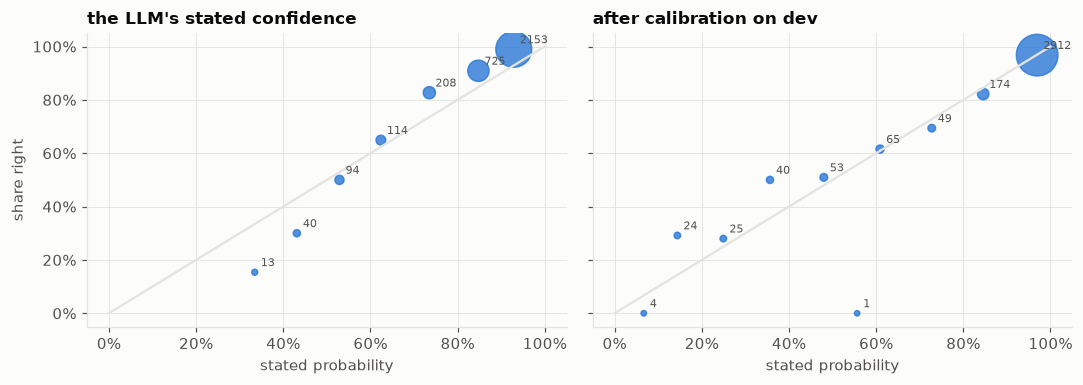

In [7]:
picked = np.array([o.chosen_code is not None for o in dev_outs])
stated = np.array([max(o.scores.values()) if o.scores else 0.0 for o in dev_outs])
ok = np.array([o.chosen_code == t for o, t in zip(dev_outs, target)])
bands = pd.cut(stated[picked] * 100, [-1, 49, 69, 79, 89, 94, 100], labels=["0–49", "50–69", "70–79", "80–89", "90–94", "95–100"])
table = pd.DataFrame({"band": bands, "right": ok[picked]}).groupby("band", observed=False)["right"].agg(["size", "mean"])
table.columns = ["picks", "right"]
table["share of picks"] = table["picks"] / picked.sum()
display(table[["picks", "share of picks", "right"]].iloc[::-1].style.format({"share of picks": "{:.1%}", "right": "{:.1%}"}))
print("most common stated values:", {f"{v:.0%}": int(n) for v, n in pd.Series(stated[picked]).round(2).value_counts().head(5).items()})
confidence = np.array([d.confidence for d in mapper.map(dev_accounts, shortlists=dev_lists)])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, vals, title in ((axes[0], stated, "the LLM's stated confidence"), (axes[1], confidence, "after calibration on dev")):
    bins = reliability_bins(vals[picked], ok[picked], n_bins=10)
    ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.5)
    ax.scatter([b["mean_p"] for b in bins], [b["accuracy"] for b in bins], s=[12 + b["n"] / 4 for b in bins], color=SINGLE, alpha=0.8)
    for b in bins:
        ax.annotate(str(b["n"]), (b["mean_p"], b["accuracy"]), xytext=(4, 4), textcoords="offset points", fontsize=7, color=INK_2)
    ax.set_xlabel("stated probability"); ax.set_title(title)
    ax.xaxis.set_major_formatter(pct()); ax.yaxis.set_major_formatter(pct())
axes[0].set_ylabel("share right")
plt.tight_layout(); plt.show()

- **Claude's own confidence is already close to honest, unlike Laya's.** Picks it gives 95–100 are right 99.8% of the time, 90–94 98.4%, 80–89 90.9%, 50–69 58.2%. If anything it is a little modest.
- **But it uses few values:** 95, 90, 92, 85 and 93 make up most of the picks. 64% of picks are at 90 or above. So the thresholds can only fall between those values, which is why the precision comes out at 99.6% instead of 98%.
- **Calibration** keeps it on the diagonal and adds the code segment. The same stated 92% means more when the account's code agrees with the pick.

## 7. Do the neighbours help?

The prompt shows the 2 accounts above and below each account, and the plan assumed that helps. The same 600 accounts and settings, with the neighbours left out (60 new calls the first time this notebook ran, then cached):

In [8]:
# The same 600 accounts and settings, with the neighbouring names left out. New questions: asked once, then cached.
bare = [a.model_copy(update={"before": [], "after": []}) for a in s_accounts]
m = LLMMethod(ClaudeCLIBackend(effort=config.models.mapping.llm_effort), config.models.mapping_model, chart, cache=cache,
              batch_size=config.models.mapping.llm_batch_size, max_calls=100)
start = time.time()
without = m.score(bare, s_lists)
print(f"without neighbours: {m.last_usage['calls']} new calls, {time.time() - start:.0f} s")
with_ = [dev_outs[i] for i in idx]
legacy = np.array([r.code_scheme == "legacy" for r in s_rows])
rows = []
for name, outs in (("with neighbours (the method)", with_), ("without neighbours", without)):
    p = np.array([o.chosen_code == t for o, t in zip(outs, s_target)])
    rows.append({"input": name, "top-1": p.mean(), "rules": p[s_source == "rules"].mean(), "LLM-written": p[s_source == "llm"].mean(),
                 "legacy code": p[legacy].mean(), "says none": np.mean([o.status == "none" for o in outs])})
display(pd.DataFrame(rows).set_index("input").style.format("{:.1%}"))

without neighbours: 0 new calls, 0 s


,top-1,rules,LLM-written,legacy code,says none
input,,,,,
with neighbours (the method),85.8%,97.3%,74.3%,83.3%,4.8%
without neighbours,85.7%,97.3%,74.0%,82.7%,5.0%


- **The neighbours make no difference:** top-1 85.8% with them, 85.7% without, on every source and on legacy codes. That is within noise.
- **Why not?** In a call of 10 consecutive accounts, Claude already sees 9 other accounts of the same company around each one. The neighbour lines mostly repeat what's in the call. And the account's own name and code carry nearly all the information.
- **They stay in the prompt for now:** they cost little (a few names per account) and could matter for one-account calls. Leaving them out is a possible saving to test in Task 3.5.

## 8. How stable are the answers?

An LLM can answer the same question differently twice. The cache freezes the first answer, so every run reads the same one. But how much does that first answer depend on chance? 10 calls asked a second time (100 accounts from 10 of the 12 sampled companies, 40 of them LLM-written):

In [9]:
# 10 calls asked a second time: the third call (accounts 21-30) of 10 of the 12 sampled companies, so both
# sources are in it. A separate cache file keeps the second answers, so this notebook asks only once.
within, seen = [], {}
for r in s_rows:
    within.append(seen.get(r.company_id, 0))
    seen[r.company_id] = within[-1] + 1
ten = list(dict.fromkeys(r.company_id for r in s_rows))[:10]
sel = [j for j, r in enumerate(s_rows) if r.company_id in ten and 20 <= within[j] < 30]
repeat = LLMMethod(ClaudeCLIBackend(effort=config.models.mapping.llm_effort), config.models.mapping_model, chart,
                   cache=AnswerCache(config.root / ".cache" / "llm" / "repeat.sqlite"), batch_size=config.models.mapping.llm_batch_size, max_calls=10)
second = repeat.score([s_accounts[j] for j in sel], [s_lists[j] for j in sel])
first = [with_[j] for j in sel]
print(f"{len(sel)} accounts ({sum(s_source[j] == 'llm' for j in sel)} LLM-written)")
same = np.array([a.chosen_code == b.chosen_code for a, b in zip(first, second)])
gap = np.array([abs(max(a.scores.values()) - max(b.scores.values())) for a, b in zip(first, second) if a.scores and b.scores])
print(f"{repeat.last_usage['calls']} new calls; same choice on {same.mean():.0%} of the {len(sel)} accounts; confidence moved by {np.median(gap) * 100:.0f} points (median), at most {gap.max() * 100:.0f}")
r1 = np.array([o.chosen_code == s_target[j] for o, j in zip(first, sel)]); r2 = np.array([o.chosen_code == s_target[j] for o, j in zip(second, sel)])
print(f"top-1: first asking {r1.mean():.0%}, second asking {r2.mean():.0%}")
display(pd.DataFrame([{"account": s_rows[sel[j]].name, "right group": s_rows[sel[j]].target_code, "first": first[j].chosen_code or first[j].status,
                       "second": second[j].chosen_code or second[j].status} for j in np.flatnonzero(~same)]).style.hide(axis="index"))

100 accounts (40 LLM-written)
8 new calls; same choice on 97% of the 100 accounts; confidence moved by 1 points (median), at most 25
top-1: first asking 90%, second asking 89%


account,right group,first,second
HANDELSVORDERINGEN - VOORUITBETALINGEN / CRÉANCES COMMERCIALES - ACOMPTES VERSÉÉS - intern,406,406,281
kredietinstellingen / etabliss,550,430,550
Kaskrediet vaste termijn,430,430,173


- **Claude gave the same choice on 97 of the 100 accounts.** Its confidence moved by 1 point (median), at most 25.
- **Top-1: 90% the first time, 89% the second.** The 3 that changed are hard cases (an internal trade receivable, two bank credit lines): the first answer was right on two of them, the second on one.
- **So the cache matters for reproducibility, not for the result.** A full rerun without the cache would land within about a point. The cache is what makes the evaluation run and this notebook give the same numbers every time.

## 9. What is *not* happening

- **No training on our data.** Claude is used as it is. Only the calibrator (three numbers) and the thresholds are fitted, on dev, as for every method.
- **No answer outside the shortlist is accepted.** Even when Claude names the right group from another account's list (section 4), the account goes to review as `invalid`.
- **No separate bill.** The calls run on the Claude login through the CLI. The $0.29 per 1,000 accounts is the CLI's estimate at API prices, which is what a deployment on the API would pay.
- **The test split is not touched.** Every number here is on dev, or on the 600-account sample of dev companies.
- **Every call is isolated:** no tools, no settings, no project files, an empty working folder (`ClaudeCLIBackend`). Claude sees only the prompt.